# 01 · Exploratory Data Analysis (Q2)

**คำถามวิจัย Q2** — ข้อมูลมีการกระจายอย่างไร และความไม่สมดุลของคลาสส่งผลต่อการเลือก metric อย่างไร?

โปรเจกต์: การทำนายโรคหลอดเลือดสมอง (Stroke) + อธิบายผลด้วย SHAP / LIME
ชุดข้อมูล: *Stroke Prediction Dataset* — 5,110 records, 12 คอลัมน์

> ในเล่มนี้เรายัง **ไม่แก้ไขข้อมูล** — ดูตามสภาพจริงก่อน แล้วค่อยทำความสะอาด

## 1. เตรียมสภาพแวดล้อม

In [1]:
import sys
from pathlib import Path

# ให้ import src ได้ไม่ว่าจะเปิด notebook จากโฟลเดอร์ไหน
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Project root:", ROOT)

Project root: D:\Stroke Prediction Dataset\Stroke-Prediction-XAI


In [2]:
def show_figure(relative_path: str, width: int = 950):
    """แสดงรูปที่ pipeline สร้างไว้ใน reports/figures"""
    path = ROOT / "reports" / "figures" / relative_path
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"[ไม่พบรูป] {path} — รัน `python -m src.run_pipeline` ก่อน")

## 2. โหลดข้อมูล

In [3]:
from src import config as cfg
from src import data_loader as dl

raw = dl.load_raw()
print("ขนาดข้อมูลดิบ:", raw.shape)
raw.head()

ขนาดข้อมูลดิบ: (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. คุณภาพข้อมูล (Data Quality)

In [4]:
quality = dl.data_quality_report(raw)
quality

,column,dtype,n_missing,pct_missing,n_unique,sample_values
0,id,int64,0,0.00,5110,"9046, 51676, 31112, 60182"
1,gender,str,0,0.00,3,"Male, Female, Other"
2,age,float64,0,0.00,104,"67.0, 61.0, 80.0, 49.0"
3,hypertension,int64,0,0.00,2,"0, 1"
4,heart_disease,int64,0,0.00,2,"1, 0"
5,ever_married,str,0,0.00,2,"Yes, No"
6,work_type,str,0,0.00,5,"Private, Self-employed, Govt_job, children"
7,Residence_type,str,0,0.00,2,"Urban, Rural"
8,avg_glucose_level,float64,0,0.00,3979,"228.69, 202.21, 105.92, 171.23"
9,bmi,float64,201,3.93,418,"36.6, 32.5, 34.4, 24.0"


In [5]:
clean = dl.basic_clean(raw)
print("ก่อนทำความสะอาด:", raw.shape[0], "แถว")
print("หลังทำความสะอาด:", clean.shape[0], "แถว")
print()
print("แถวที่ถูกลบ:", raw.shape[0] - clean.shape[0], "(gender = 'Other' มีเพียง 1 แถว)")
print("คอลัมน์ที่ถูกลบ: id (ไม่มีข้อมูลเชิงทำนาย)")
print()
print("ค่าที่หายคงเหลือ (จะถูกเติมใน pipeline):")
print(clean.isna().sum()[clean.isna().sum() > 0])

ก่อนทำความสะอาด: 5110 แถว
หลังทำความสะอาด: 5109 แถว

แถวที่ถูกลบ: 1 (gender = 'Other' มีเพียง 1 แถว)
คอลัมน์ที่ถูกลบ: id (ไม่มีข้อมูลเชิงทำนาย)

ค่าที่หายคงเหลือ (จะถูกเติมใน pipeline):
bmi    201
dtype: int64


### 🧭 ข้อสังเกตจากคุณภาพข้อมูล

| ประเด็น | รายละเอียด | การจัดการ |
|---|---|---|
| `id` | ตัวระบุ ไม่มีความหมายเชิงทำนาย | ตัดออก |
| `gender = 'Other'` | มีเพียง 1 แถว | ตัดออก (ไม่มีอำนาจทางสถิติ) |
| `bmi` ขาด 3.93% | 201 records | เติมด้วย median **ภายใน** sklearn Pipeline (กัน leakage) |
| `smoking_status = 'Unknown'` | 30.22% | คงไว้เป็นอีก level หนึ่ง (การเดาค่าอาจสร้างอคติ) |

## 4. ความไม่สมดุลของคลาส — หัวใจของ Q2

In [6]:
counts = clean[cfg.TARGET].value_counts().sort_index()
summary = pd.DataFrame({
    "จำนวน": counts.values,
    "สัดส่วน (%)": (counts / counts.sum() * 100).round(3).values,
}, index=["No Stroke (0)", "Stroke (1)"])
summary.loc["รวม"] = [counts.sum(), 100.0]

imbalance = counts[0] / counts[1]
baseline_acc = counts[0] / counts.sum() * 100

display(summary)
print(f"อัตราส่วน class imbalance = {imbalance:.1f} : 1")
print(f"ถ้าทำนาย 'ไม่เป็น stroke' ทุกคน จะได้ Accuracy = {baseline_acc:.2f}%")
print("=> Accuracy ใช้ไม่ได้กับข้อมูลชุดนี้ ต้องใช้ Recall / F1 / PR-AUC / Confusion Matrix")

,จำนวน,สัดส่วน (%)
No Stroke (0),4860.0,95.126
Stroke (1),249.0,4.874
รวม,5109.0,100.000


อัตราส่วน class imbalance = 19.5 : 1
ถ้าทำนาย 'ไม่เป็น stroke' ทุกคน จะได้ Accuracy = 95.13%
=> Accuracy ใช้ไม่ได้กับข้อมูลชุดนี้ ต้องใช้ Recall / F1 / PR-AUC / Confusion Matrix


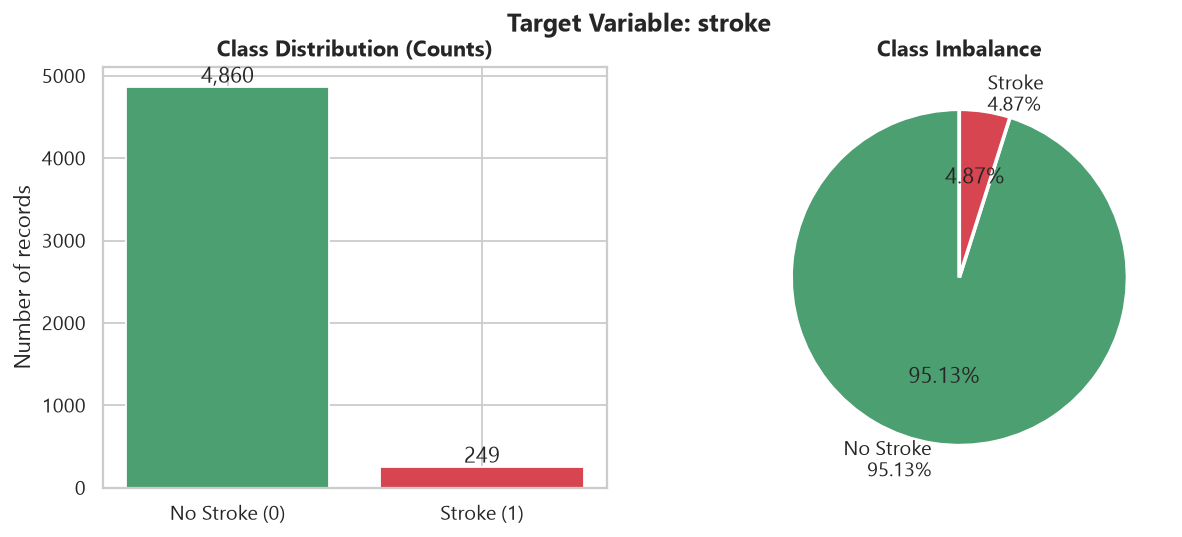

In [7]:
show_figure("eda/01_target_distribution.png")

> **Insight Q2.1** — เพราะคลาสบวกมีเพียง **4.87%** โมเดลที่ "ทายไม่เป็น stroke ทั้งหมด"
> จะได้ Accuracy สูงถึง ~95% แต่ **Recall = 0** ซึ่งไร้ประโยชน์ทางคลินิก
> เราจึงต้องเปลี่ยน metric เป้าหมายเป็น **Recall / F1 / PR-AUC** และดู **Confusion Matrix**
> เพื่อนับจำนวนผู้ป่วยที่ถูกมองข้าม (FN) เป็นรายคน

## 5. การกระจายของตัวแปรต่อเนื่อง

In [8]:
desc = clean[list(cfg.NUMERIC_FEATURES) + [cfg.TARGET]].groupby(cfg.TARGET).describe().T
desc

stroke                             0           1
age               count  4860.000000  249.000000
                  mean     41.974831   67.728193
                  std      22.293056   12.727419
                  min       0.080000    1.320000
                  25%      24.000000   59.000000
                  50%      43.000000   71.000000
                  75%      59.000000   78.000000
                  max      82.000000   82.000000
avg_glucose_level count  4860.000000  249.000000
                  mean    104.787584  132.544739
                  std      43.847095   61.921056
                  min      55.120000   56.110000
                  25%      77.120000   79.790000
                  50%      91.465000  105.220000
                  75%     112.800000  196.710000
                  max     267.760000  271.740000
bmi               count  4699.000000  209.000000
                  mean     28.824431   30.471292
                  std       7.908573    6.329452
                  min      10.300000   16.900000
                  25%      23.400000   26.400000
                  50%      28.000000   29.700000
                  75%      33.100000   33.700000
                  max      97.600000   56.600000

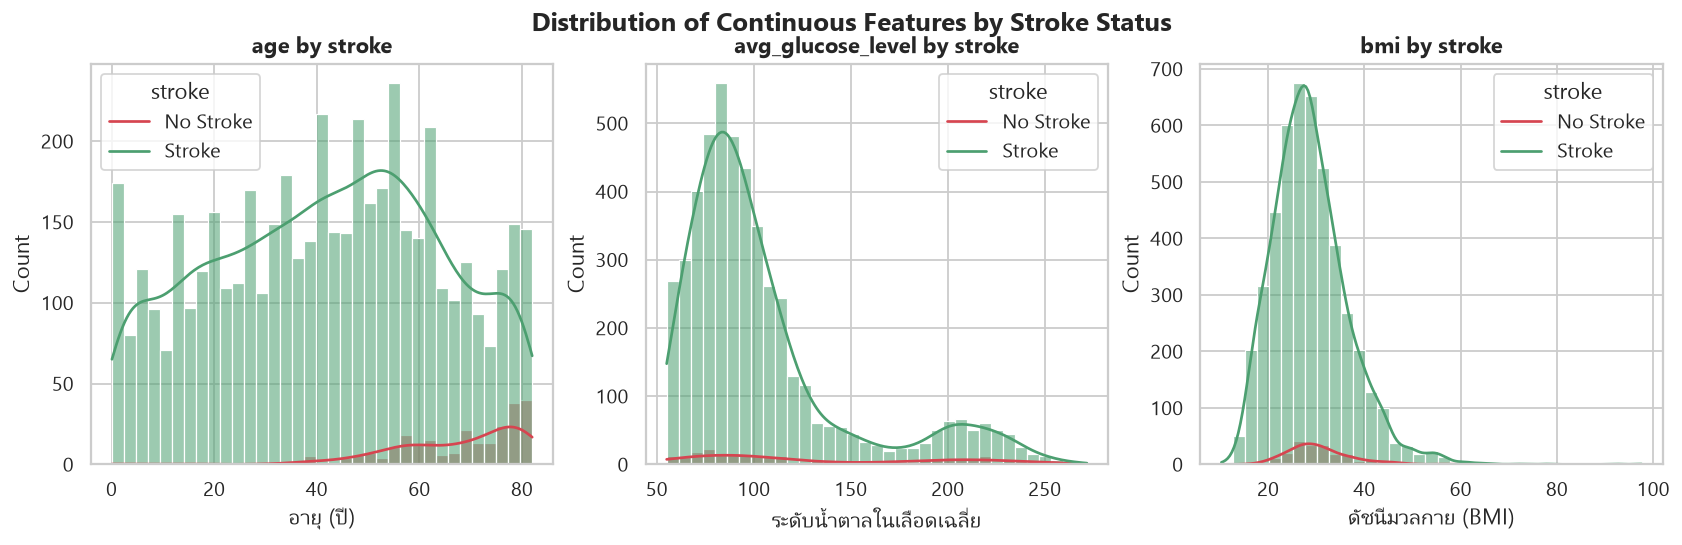

In [9]:
show_figure("eda/03_numeric_distributions.png", 1100)

**อ่านกราฟ**: อายุของกลุ่ม stroke กระจายไปทางค่ามากอย่างชัดเจน (มัธยฐาน 71 vs 43 ปี)
ส่วน `avg_glucose_level` และ `bmi` กลุ่ม stroke มีค่าสูงกว่าเล็กน้อยแต่ทับซ้อนกันมาก
→ บอกได้ว่าอายุคือตัวแปรที่แยกกลุ่มได้ชัดที่สุด (จะยืนยันด้วยสถิติใน notebook 02)

## 6. ตัวแปรเชิงกลุ่ม vs สถานะ Stroke

In [10]:
for col in cfg.CATEGORICAL_FEATURES:
    tbl = pd.crosstab(clean[col], clean[cfg.TARGET], normalize="index").mul(100).round(2)
    tbl.columns = ["No Stroke (%)", "Stroke (%)"]
    print(f"--- {col} ---")
    display(tbl)
    print()

--- gender ---

,No Stroke (%),Stroke (%)
gender,,
Female,95.29,4.71
Male,94.89,5.11



--- ever_married ---


,No Stroke (%),Stroke (%)
ever_married,,
No,98.35,1.65
Yes,93.44,6.56



--- work_type ---


,No Stroke (%),Stroke (%)
work_type,,
Govt_job,94.98,5.02
Never_worked,100.00,0.00
Private,94.90,5.10
Self-employed,92.06,7.94
children,99.71,0.29



--- Residence_type ---


,No Stroke (%),Stroke (%)
Residence_type,,
Rural,95.46,4.54
Urban,94.80,5.20



--- smoking_status ---


,No Stroke (%),Stroke (%)
smoking_status,,
Unknown,96.96,3.04
formerly smoked,92.08,7.92
never smoked,95.24,4.76
smokes,94.68,5.32


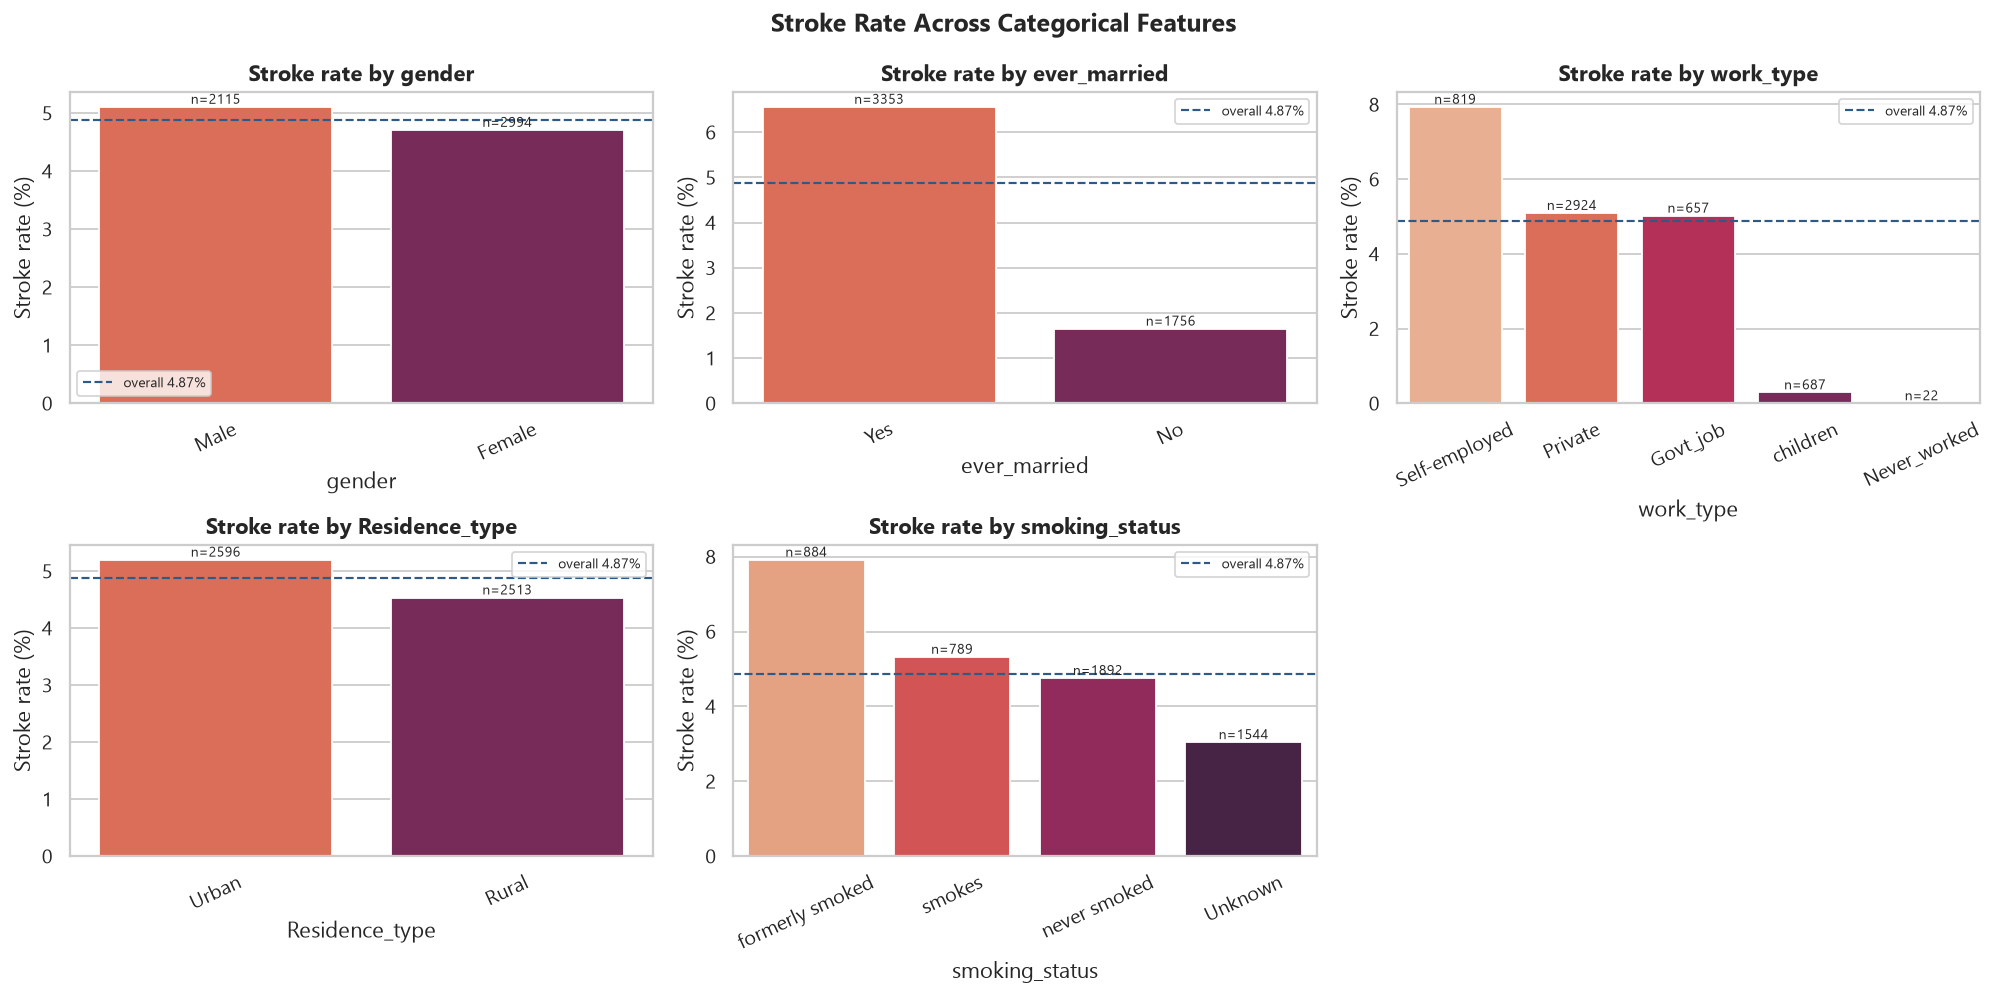

In [11]:
show_figure("eda/04_categorical_vs_target.png", 1150)

> **Insight Q2.2** — `smoking_status = 'Unknown'` มีสัดส่วนสูงถึง 30% (1,544 ราย)
> หากสัดส่วนการเกิด stroke ในกลุ่มนี้ไม่ต่างจากกลุ่มอื่น อาจแปลว่าค่า "Unknown"
> เป็น **Missing Not At Random** ที่อาจกลบความสัมพันธ์ที่แท้จริงของการสูบบุหรี่
> เป็นข้อจำกัดที่ต้องรายงานในเล่มสรุป

## 7. ความสัมพันธ์ระหว่างตัวแปร

In [12]:
num_cols = list(cfg.NUMERIC_FEATURES) + list(cfg.BINARY_FEATURES) + [cfg.TARGET]
clean[num_cols].corr(method="spearman").round(3)

,age,avg_glucose_level,bmi,hypertension,heart_disease,stroke
age,1.000,0.145,0.375,0.281,0.270,0.250
avg_glucose_level,0.145,1.000,0.115,0.114,0.106,0.083
bmi,0.375,0.115,1.000,0.167,0.066,0.055
hypertension,0.281,0.114,0.167,1.000,0.108,0.128
heart_disease,0.270,0.106,0.066,0.108,1.000,0.135
stroke,0.250,0.083,0.055,0.128,0.135,1.000


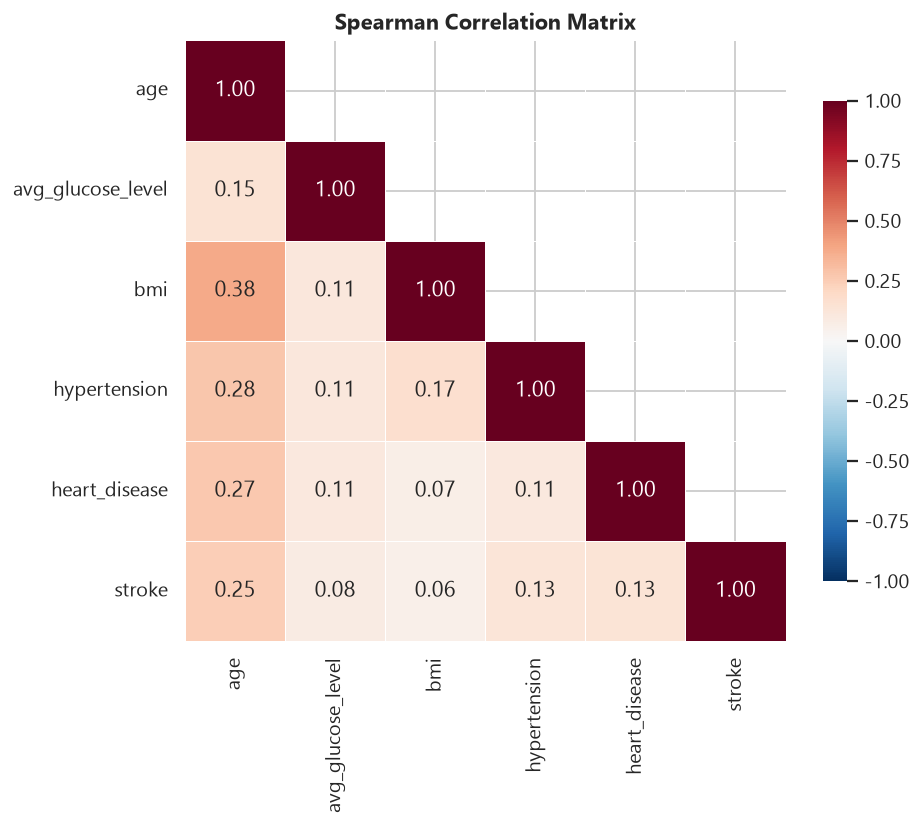

In [13]:
show_figure("eda/05_correlation_heatmap.png", 800)

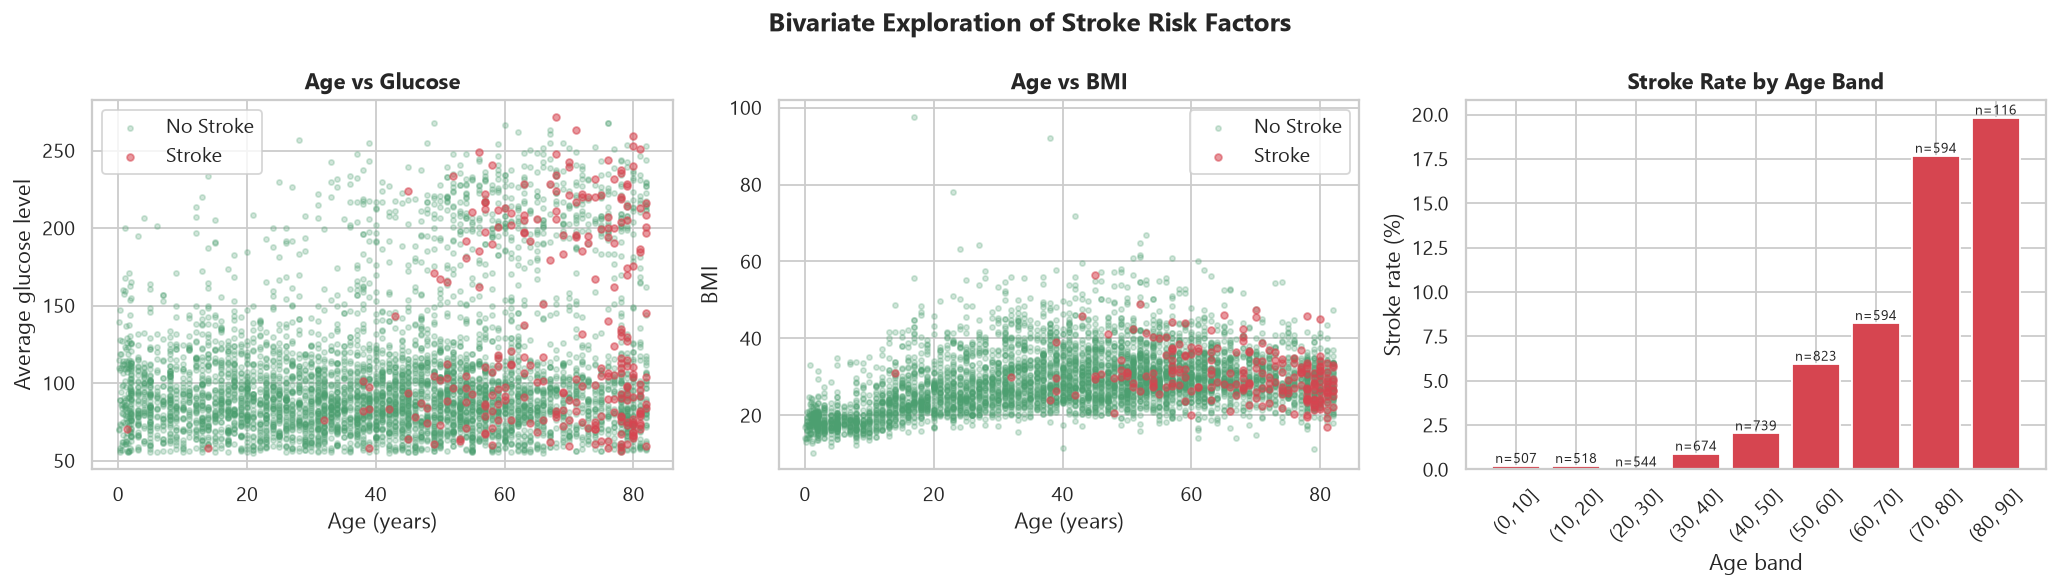

In [14]:
show_figure("eda/06_scatter_age_glucose_bmi.png", 1250)

## 8. ภาระความเสี่ยงหลอดเลือด (Vascular Risk Burden)

In [15]:
tmp = clean.copy()
tmp["vascular_risk"] = tmp["hypertension"].astype(int) + tmp["heart_disease"].astype(int)
tbl = tmp.groupby("vascular_risk")[cfg.TARGET].agg(stroke_rate="mean", n="count")
tbl["stroke_rate_%"] = (tbl["stroke_rate"] * 100).round(2)
tbl[["n", "stroke_rate_%"]]

,n,stroke_rate_%
vascular_risk,,
0,4399,3.39
1,646,13.47
2,64,20.31


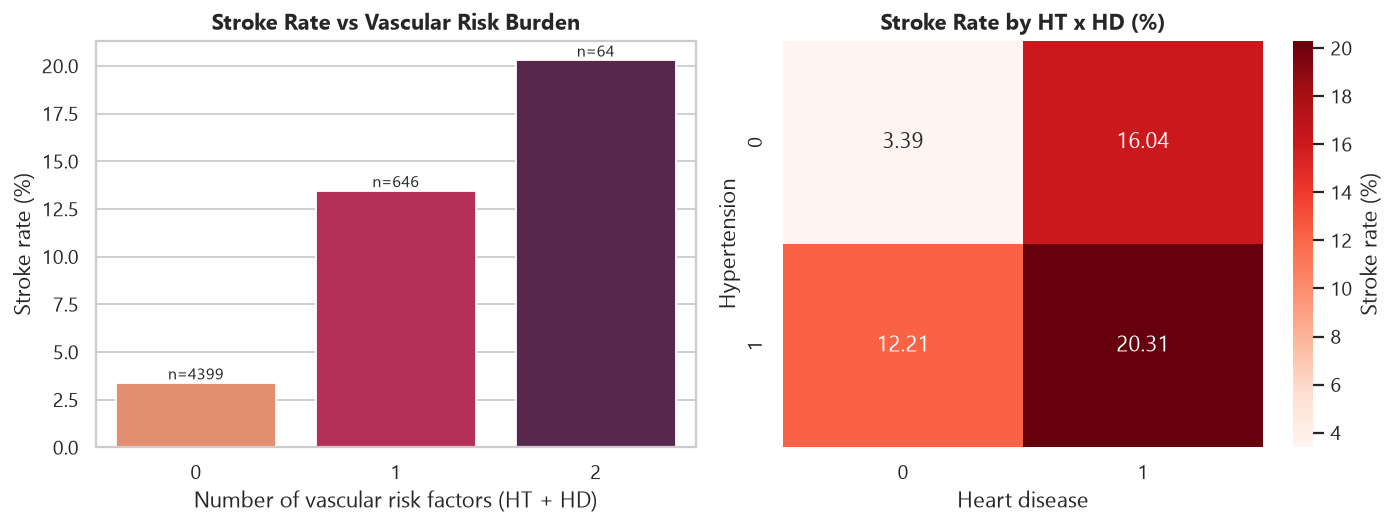

In [16]:
show_figure("eda/07_vascular_risk.png", 1050)

> **Insight Q2.3** — จำนวนปัจจัยเสี่ยง (ความดันโลหิตสูง + โรคหัวใจ) มีความสัมพันธ์แบบ
> **เพิ่มขึ้นตามจำนวน (dose-response)**: ยิ่งมีปัจจัยเสี่ยงมาก อัตราการเกิด stroke ยิ่งสูงขึ้นชัดเจน
> รูปแบบนี้สนับสนุนสมมติฐานเชิงสาเหตุได้ดีกว่าตัวแปรเดี่ยว ๆ

## 9. สรุป Q2

1. **ข้อมูลไม่สมดุลรุนแรง** (19.5 : 1) → เลือก metric ที่เหมาะกับคลาสบวชนอกเสียก่อน
2. **อายุ** แยกกลุ่มได้ชัดที่สุด, รองลงมาคือ **avg_glucose_level** และ **bmi**
3. **ภาระความเสี่ยงหลอดเลือด** แสดงความสัมพันธ์แบบ dose-response
4. **คุณภาพข้อมูล** มีจุดอ่อนที่ `smoking_status = Unknown` (30%) และ `bmi` หาย 3.9%
5. ขั้นตอนถัดไป → ทดสอบนัยสำคัญทางสถิติอย่างเป็นทางการใน `02_statistical_analysis.ipynb`